# Importing Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
from scipy.stats import ttest_ind, ttest_1samp, levene, f_oneway
from scipy.stats import kruskal, kurtosis, skew, shapiro, pearsonr, spearmanr
from scipy.stats.contingency import chi2_contingency
from scipy.stats import zscore
from statsmodels.graphics.gofplots import qqplot
import statsmodels.api as sm

import warnings
warnings.filterwarnings('ignore')

# Importing Yulu Dataset

In [ ]:
!gdown 1z7MrzLNJMRhxCet_wYroS0X551DWPbEj

Downloading...
From: https://drive.google.com/uc?id=1z7MrzLNJMRhxCet_wYroS0X551DWPbEj
To: /content/bike_sharing.csv
100% 648k/648k [00:00<00:00, 111MB/s]


In [ ]:
df = pd.read_csv('bike_sharing.csv')

# Initial Data Inspection

In [ ]:
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [ ]:
df.shape

(10886, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [ ]:
df.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


## Value Counts

In [ ]:
# Filtering all Numeric columns

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

In [ ]:
# Value Counts for all Numeric Columns

for col in numeric_cols:
  print(f'Value Counts for {col}')
  print(df[col].value_counts())

Value Counts for season
season
4    2734
2    2733
3    2733
1    2686
Name: count, dtype: int64
Value Counts for holiday
holiday
0    10575
1      311
Name: count, dtype: int64
Value Counts for workingday
workingday
1    7412
0    3474
Name: count, dtype: int64
Value Counts for weather
weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64
Value Counts for temp
temp
14.76    467
26.24    453
28.70    427
13.94    413
18.86    406
22.14    403
25.42    403
16.40    400
22.96    395
27.06    394
24.60    390
12.30    385
21.32    362
17.22    356
13.12    356
29.52    353
10.66    332
18.04    328
20.50    327
30.34    299
9.84     294
15.58    255
9.02     248
31.16    242
8.20     229
27.88    224
23.78    203
32.80    202
11.48    181
19.68    170
6.56     146
33.62    130
5.74     107
7.38     106
31.98     98
34.44     80
35.26     76
4.92      60
36.90     46
4.10      44
37.72     34
36.08     23
3.28      11
0.82       7
38.54      7
39.36      6
2.46       5


## Unique Values in Each Columns

In [ ]:
for col in df.columns:
    print(col, df[col].nunique())

datetime 10886
season 4
holiday 2
workingday 2
weather 4
temp 49
atemp 60
humidity 89
windspeed 28
casual 309
registered 731
count 822


# Business Problem

The company wants to know:

1. Which variables are significant in predicting the demand for shared electric cycles in the Indian market?
2. How well those variables describe the electric cycle demands

## Missing Values

In [ ]:
missing_value = pd.DataFrame({
    'Missing Value': df.isnull().sum(),
     'Percentage': (df.isnull().sum() / len(df))*100
})
missing_value.sort_values(by='Percentage', ascending=False)

,Missing Value,Percentage
datetime,0,0.0
season,0,0.0
holiday,0,0.0
workingday,0,0.0
weather,0,0.0
temp,0,0.0
atemp,0,0.0
humidity,0,0.0
windspeed,0,0.0
casual,0,0.0


## Type Conversion

In [ ]:
# Converting date column to datetime format

df['datetime'] = pd.to_datetime(df['datetime'])

In [ ]:
# Extracting hour for additional insights

df['hour'] = df['datetime'].dt.hour.astype('int64')

In [ ]:
# Converting numerical columns into categorical columns as these columns have grouped values

cat_cols = ['season', 'holiday', 'workingday', 'weather']

for col in cat_cols:
  df[col] = df[col].astype('object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  object        
 2   holiday     10886 non-null  object        
 3   workingday  10886 non-null  object        
 4   weather     10886 non-null  object        
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
 12  hour        10886 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(5), object(4)
memory usage: 1.1+ MB


## Outliers Detection

### Distribution Plot

In [ ]:
num_cols = ['temp', 'atemp', 'humidity', 'windspeed', 'count']

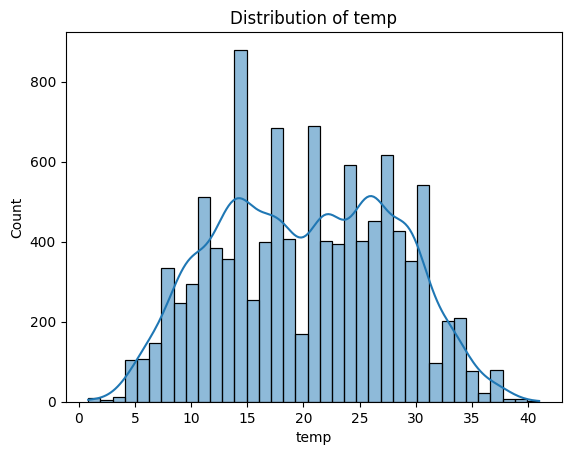

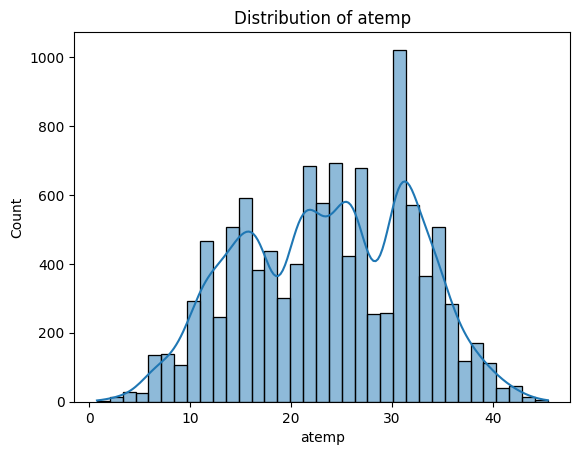

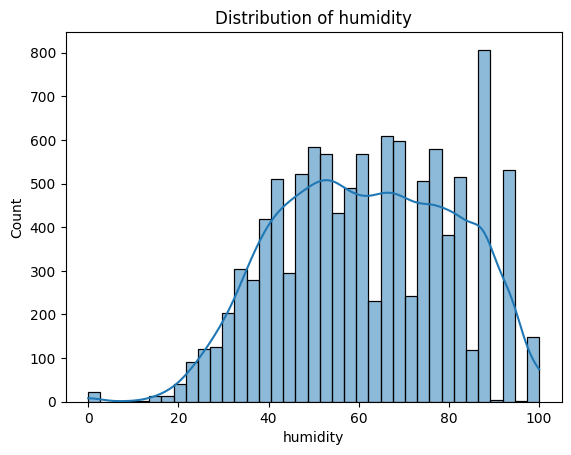

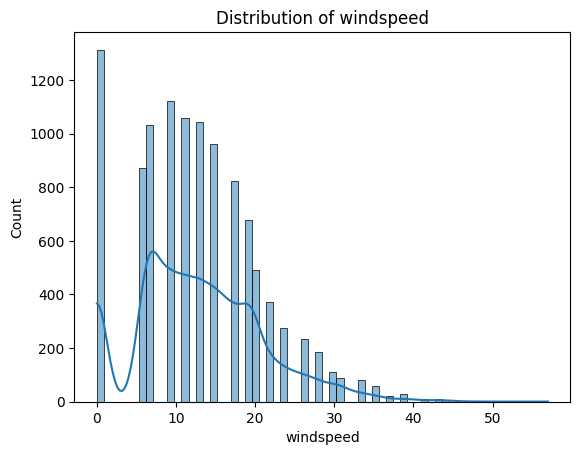

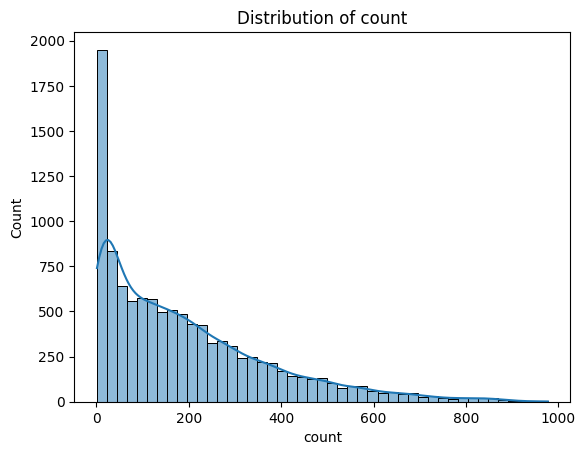

In [ ]:
for col in num_cols:
    plt.figure()
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

### Box Plot

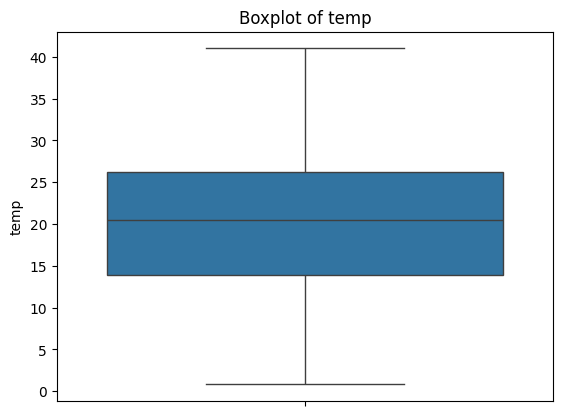

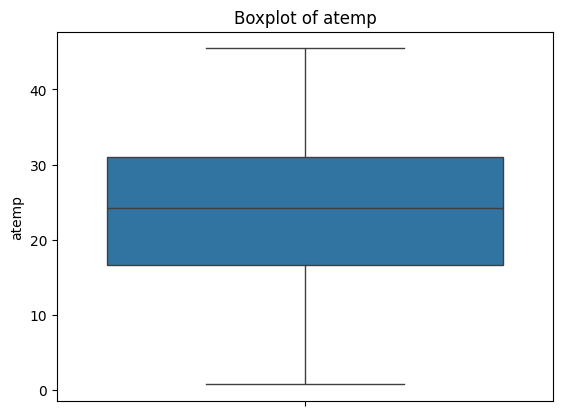

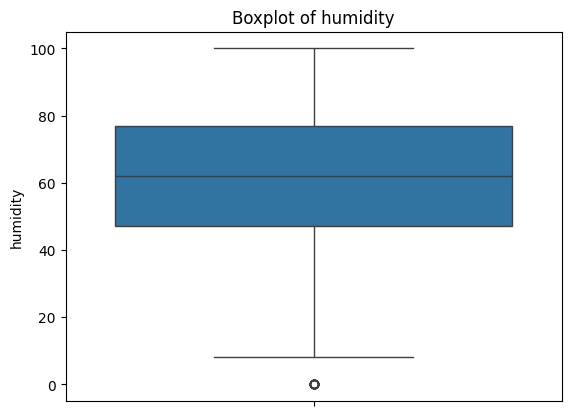

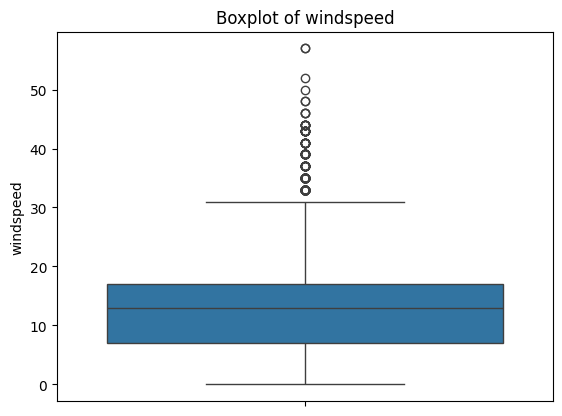

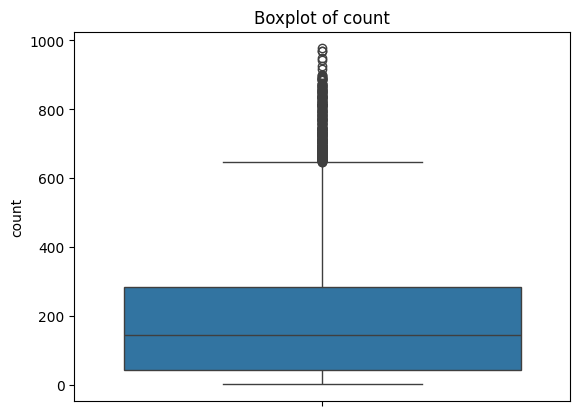

In [ ]:
for col in num_cols:
  plt.figure()
  sns.boxplot(y=df[col])
  plt.title(f'Boxplot of {col}')
  plt.show()

### IQR Method

In [ ]:
for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower) | (df[col] > upper)]

  print(f"{col}: {len(outliers)} outliers")

temp: 0 outliers
atemp: 0 outliers
humidity: 22 outliers
windspeed: 227 outliers
count: 300 outliers


### Z-score

In [ ]:

numeric_df = df.select_dtypes(include=['number'])

# Compute Z-scores
z_scores = numeric_df.apply(zscore)

In [ ]:
# Set threshold (commonly 3)
threshold = 3

# Boolean mask for outliers
outliers = (np.abs(z_scores) > threshold)

# Rows that contain any outlier
outlier_rows = df[outliers.any(axis=1)]

print("Number of outlier rows:", outlier_rows.shape[0])

Number of outlier rows: 614


## Univariate Analysis

### Continuous Columns

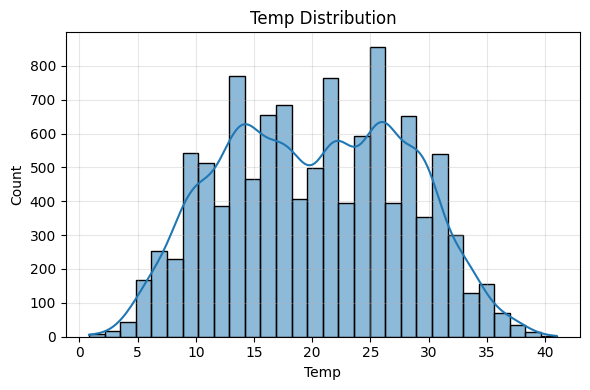

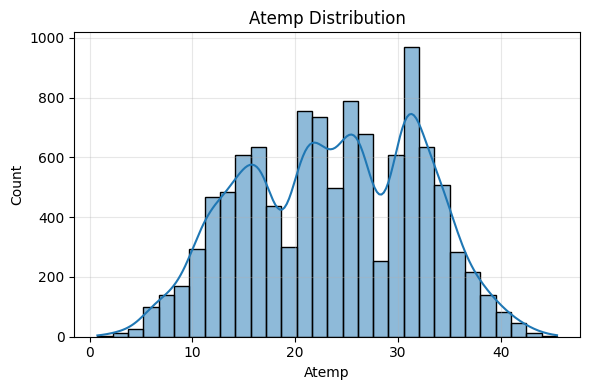

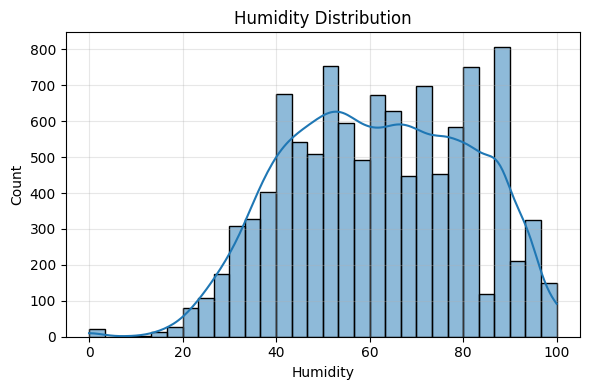

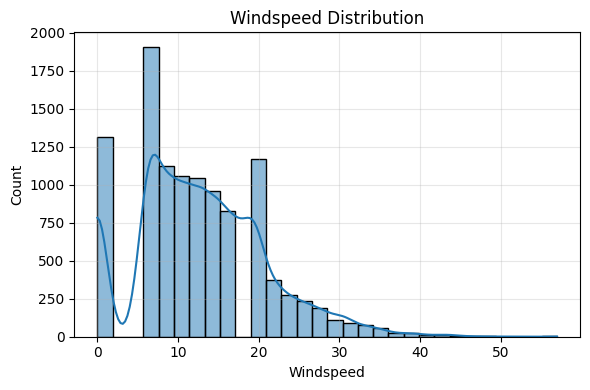

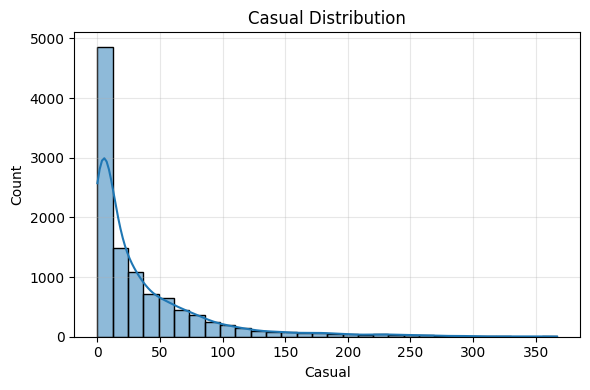

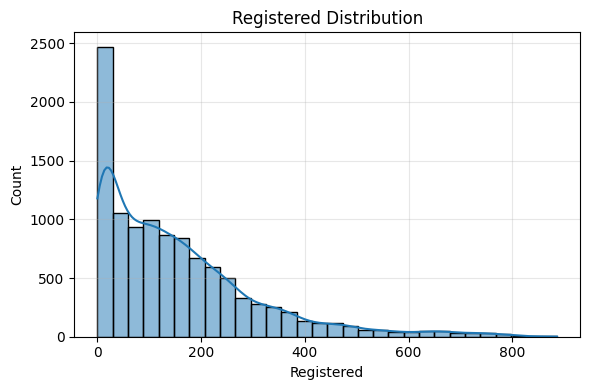

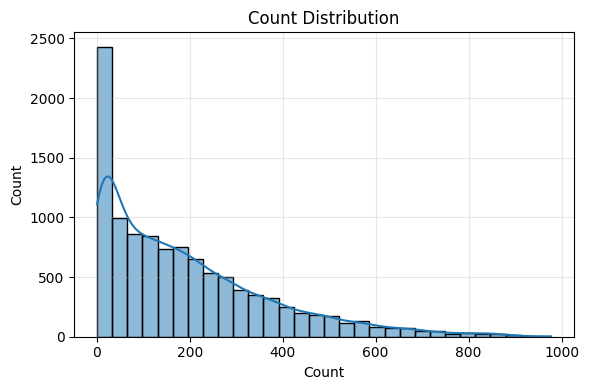

In [ ]:
# Continuous variables
cont_cols = ['temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']

for col in cont_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=col, kde=True, bins=30)
    plt.title(f'{col.replace("_", " ").title()} Distribution', fontsize=12)
    plt.xlabel(col.replace('_', ' ').title())
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Categorical Columns

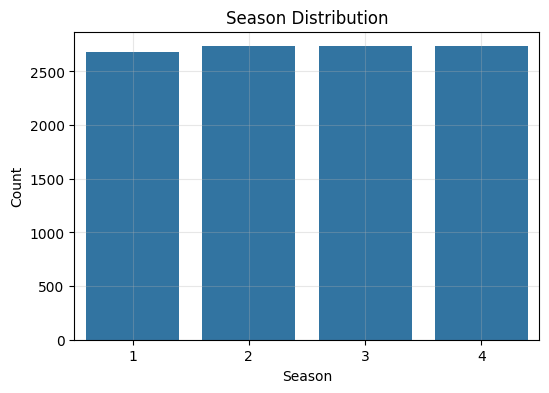

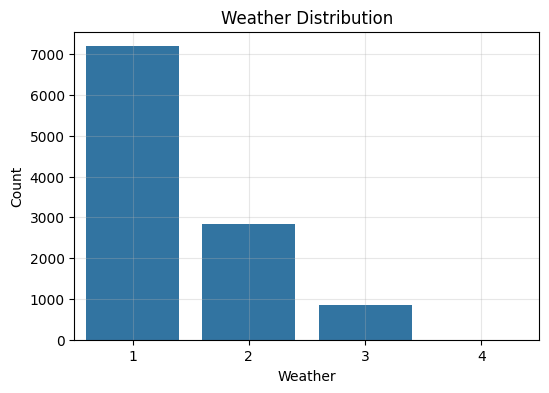

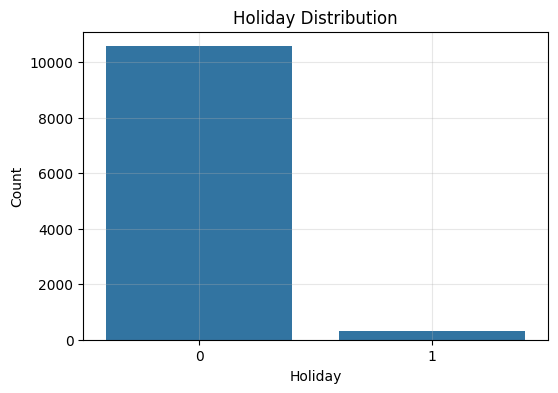

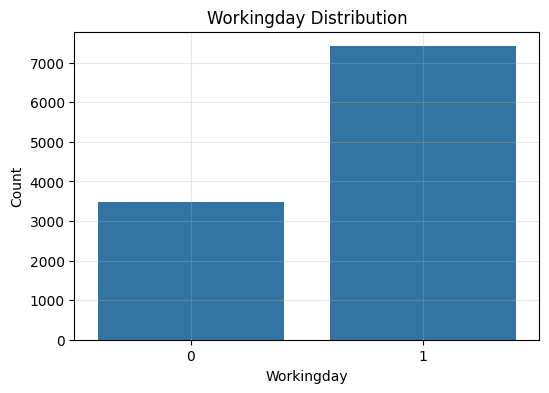

In [ ]:
# Categorical variables
cat_vars = ['season', 'weather', 'holiday', 'workingday']

for col in cat_vars:
  plt.figure(figsize=(6, 4))
  sns.countplot(data=df, x=col)
  plt.title(f'{col.title()} Distribution', fontsize=12)
  plt.xlabel(col.replace('_', ' ').title())
  plt.ylabel('Count')
  plt.grid(True, alpha=0.3)
  plt.show()

## Bivariate Analysis

### Box Plots

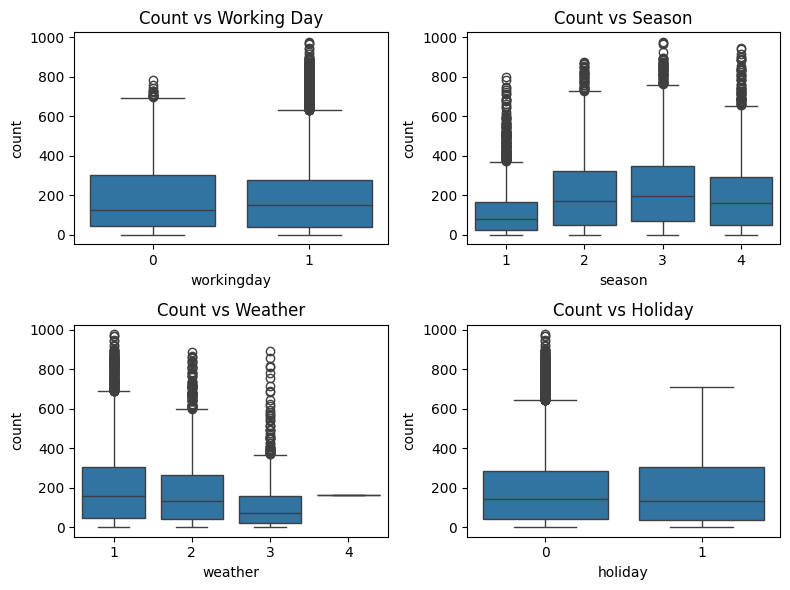

In [ ]:
plt.figure(figsize=(8, 6))

# Plot 1
plt.subplot(2, 2, 1)
sns.boxplot(data=df, x='workingday', y='count')
plt.title('Count vs Working Day')

# Plot 2
plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='season', y='count')
plt.title('Count vs Season')

# Plot 3
plt.subplot(2, 2, 3)
sns.boxplot(data=df, x='weather', y='count')
plt.title('Count vs Weather')

# Plot 4
plt.subplot(2, 2, 4)
sns.boxplot(data=df, x='holiday', y='count')
plt.title('Count vs Holiday')

plt.tight_layout()
plt.show()

### Correlation Matrix

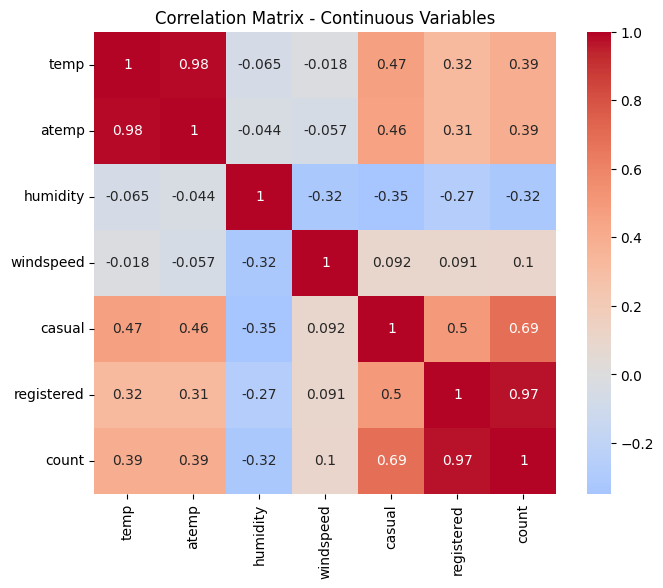

In [ ]:
# Correlation heatmap for continuous variables

plt.figure(figsize=(8, 6))
corr_matrix = df[['temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix - Continuous Variables')
plt.show()

## Assumptions

In [ ]:
alpha = 0.05

## Working day vs number of cycles rented

### Hypothesis Testing

**Step 1: Setup Null and Alternate Hypothesis**

H0: Mean number of rented cycles is the same on working days and non-working days.

H1: Mean number of rented cycles is different on working days and non-working days.

**Step 2: Choose the distribution**

Check for Normality using Shapiro Wilks Test

In [ ]:
working_day_map = { 1: "WorkingDay", 0: "Non_WorkingDay"}
df["workingday_name"] = df["workingday"].map(working_day_map)
workingday_data = df["workingday_name"].dropna().unique()
workingday_data

array(['Non_WorkingDay', 'WorkingDay'], dtype=object)

In [ ]:
for d in workingday_data:
  data = df[df['workingday_name']== d]['count'].dropna()
  stat, p_value = shapiro(data)
  print(f"Season {d}: {stat}, p-value: {p_value}")

  if p_value < alpha:
    print("→ Reject H0: Data is not normally distributed")
  else:
    print("→ Fail to reject H0: Data is approximately normal")

Season Non_WorkingDay: 0.885211755076074, p-value: 4.4728547627911074e-45
→ Reject H0: Data is not normally distributed
Season WorkingDay: 0.8702545795617624, p-value: 2.2521124830019574e-61
→ Reject H0: Data is not normally distributed


Check for variance using Levene's test

In [ ]:
non_working = df[df["workingday"] == 0]["count"]
working = df[df["workingday"] == 1]["count"]

lev_stat, lev_pvalue = levene(non_working, working)

print(f"Levene test statistic: {lev_stat}, p-value: {lev_pvalue}")

# print("Levene test statistic:", lev_stat)
# print("Levene p-value:", lev_pvalue)

if lev_pvalue < alpha:
    print("Reject H0: variances are significantly different")
else:
    print("Fail to reject H0: variances are approximately equal")

Levene test statistic: 0.004972848886504472, p-value: 0.9437823280916695
Fail to reject H0: variances are approximately equal


**Step 3: Select left vs right vs 2-tailed as per hypothesis**

Two-tailed test

**Step 4: Calculate p-value**

In [ ]:
ttest_stats, ttest_pvalue = ttest_ind(non_working, working)
print(f"ttest_stats: {ttest_stats:.4f}, p-value: {ttest_pvalue:.4f}")

ttest_stats: -1.2096, p-value: 0.2264


**Step 5: Accepting or Rejecting the Hypothesis based on p-value**

In [ ]:
if ttest_pvalue < alpha:
    print("Reject H0: Mean number of rented cycles is different on working days and non-working days.")
else:
    print("Fail to reject H0: Mean number of rented cycles is the same on working days and non-working days.")

Fail to reject H0: Mean number of rented cycles is the same on working days and non-working days.


### Bootstrap Method

In [ ]:
boot_diffs = []

for _ in range(5000):
    sample1 = np.random.choice(non_working, size=len(non_working), replace=True)
    sample2 = np.random.choice(working, size=len(working), replace=True)
    boot_diffs.append(sample2.mean() - sample1.mean())

boot_diffs = np.array(boot_diffs)

# ci_lower = np.round(np.percentile(boot_diffs, 2.5),2)
# ci_upper = np.round(np.percentile(boot_diffs, 97.5),2)

ci_lower = np.percentile(boot_diffs, 2.5)
ci_upper = np.percentile(boot_diffs, 97.5)

print("95% CI:", ci_lower, ci_upper)

95% CI: -2.7080192217353756 11.436178056651508


## Season vs number of cycles rented

In [ ]:
df.groupby('season')['count'].describe()

,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
1,2686.0,116.343261,125.273974,1.0,24.0,78.0,164.0,801.0
2,2733.0,215.251372,192.007843,1.0,49.0,172.0,321.0,873.0
3,2733.0,234.417124,197.151001,1.0,68.0,195.0,347.0,977.0
4,2734.0,198.988296,177.622409,1.0,51.0,161.0,294.0,948.0


### Hypothesis Testing

**Step 1: Setup Null and Alternate Hypothesis**


H0: Mean rentals same across all seasons

H1: At least one season has different mean rentals


**Step 2: Choose the distribution**

Check for Normality

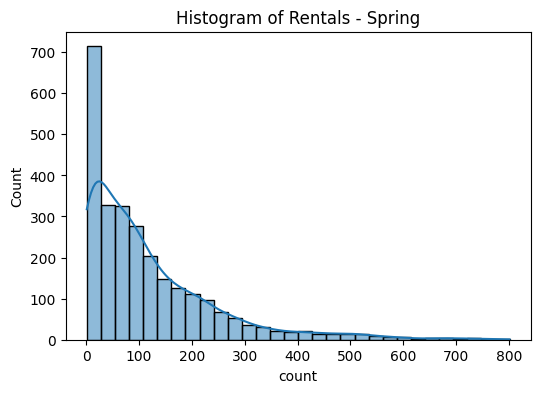

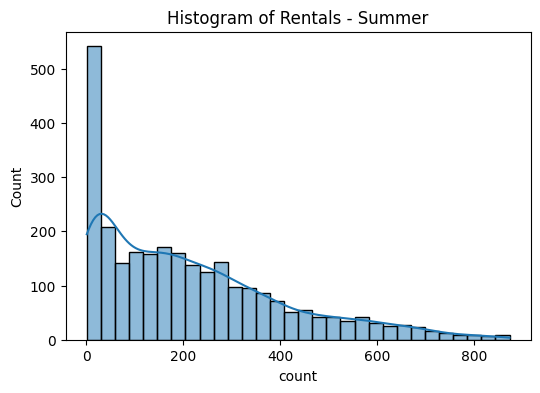

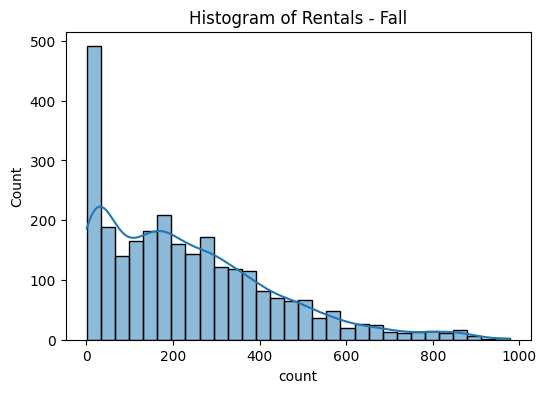

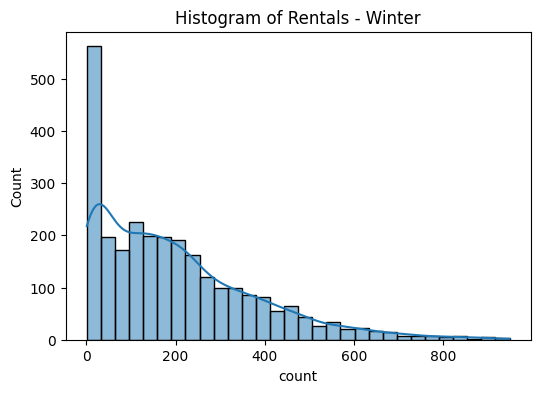

In [ ]:
# Mapping seasons

season_map = { 1: "Spring", 2: "Summer",
              3: "Fall", 4: "Winter"}
df["season_name"] = df["season"].map(season_map)
seasons = df["season_name"].dropna().unique()

# Plotting Histogram for each season

for s in seasons:
  plt.figure(figsize=(6, 4))
  sns.histplot(data=df[df["season_name"] == s], x="count", bins=30, kde=True)
  plt.title(f"Histogram of Rentals - {s}")
  plt.show()

<Figure size 600x400 with 0 Axes>

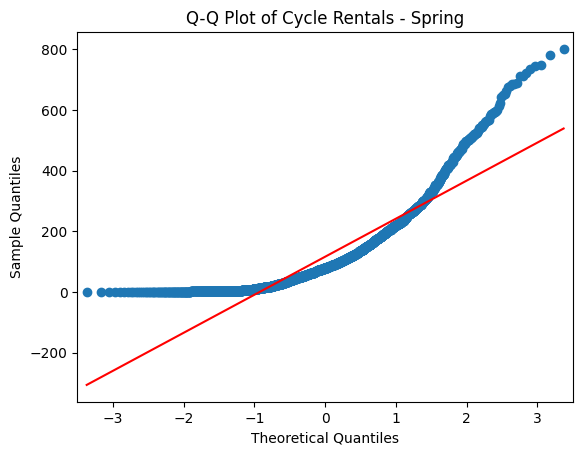

<Figure size 600x400 with 0 Axes>

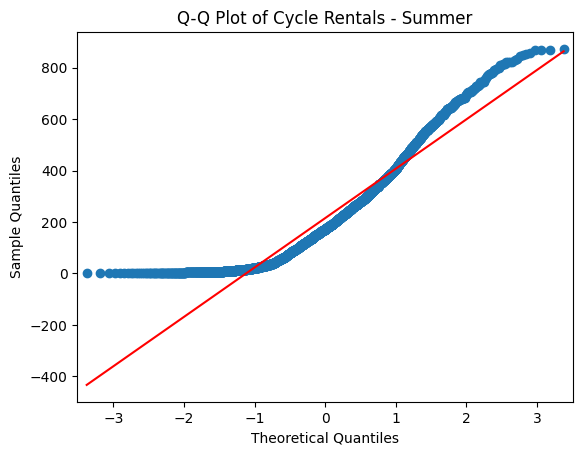

<Figure size 600x400 with 0 Axes>

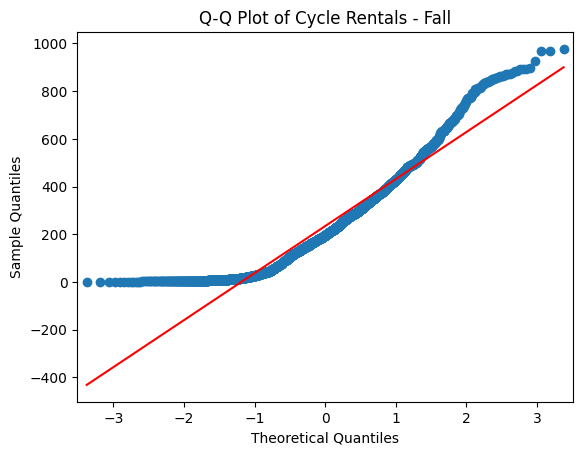

<Figure size 600x400 with 0 Axes>

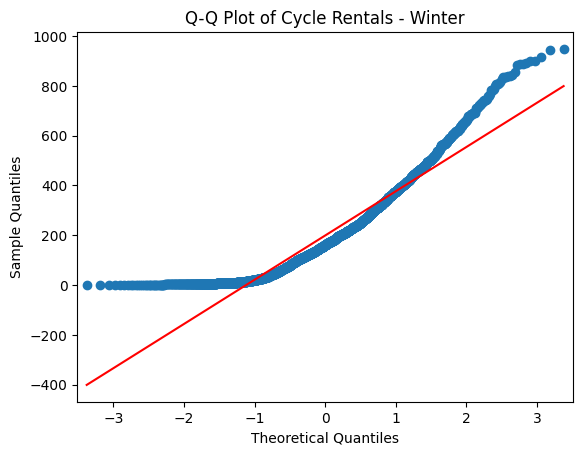

In [ ]:
# Quantile-Quantile plot for each season

for s in seasons:
  plt.figure(figsize=(6, 4))
  sm.qqplot(df[df["season_name"] == s]["count"], line='s')
  plt.title(f"Q-Q Plot of Cycle Rentals - {s}")
  plt.show()

In [ ]:
for s in seasons:
  data = df[df['season_name']== s]['count'].dropna()
  stat, p_value = shapiro(data)
  print(f"Season {s}: {stat:.4f}, p-value: {p_value:.4f}")

  if p_value < alpha:
    print("→ Reject H0: Data is not normally distributed")
  else:
    print("→ Fail to reject H0: Data is approximately normal")

Season Spring: 0.8087, p-value: 0.0000
→ Reject H0: Data is not normally distributed
Season Summer: 0.9005, p-value: 0.0000
→ Reject H0: Data is not normally distributed
Season Fall: 0.9148, p-value: 0.0000
→ Reject H0: Data is not normally distributed
Season Winter: 0.8955, p-value: 0.0000
→ Reject H0: Data is not normally distributed


In [ ]:
season1 = df[df['season'] == 1]['count']
season2 = df[df['season'] == 2]['count']
season3 = df[df['season'] == 3]['count']
season4 = df[df['season'] == 4]['count']

lev_stat, lev_pvalue = levene(season1, season2, season3, season4)

print(f"Levene test statistic: {lev_stat}, p-value: {lev_pvalue}")

if lev_pvalue < alpha:
    print("Reject H0: variances are significantly different")
else:
    print("Fail to reject H0: variances are approximately equal")

Levene test statistic: 187.7706624026276, p-value: 1.0147116860043298e-118
Reject H0: variances are significantly different


**Step 3: Select left vs right vs 2-tailed as per hypothesis**

In [ ]:
# Two Tailed

**Step 4: Calculate p-value**

In [ ]:
# Kruskal-Wallis Test

kruskal_stat, kruskal_pvalue = kruskal(season1, season2, season3, season4)

print(f"test-statistic: {kruskal_stat}, p-value: {kruskal_pvalue}")

test-statistic: 699.6668548181988, p-value: 2.479008372608633e-151


In [ ]:
# ANOVA

f_stat, anova_pvalue = f_oneway(season1, season2, season3, season4)

print(f"F-statistic: {f_stat}, p-value: {anova_pvalue}")

F-statistic: 236.94671081032098, p-value: 6.164843386499654e-149


**Step 5: Accepting or Rejecting the Hypothesis based on p-value**

In [ ]:
if kruskal_pvalue < alpha:
  print("Reject H0: At least one season has a different distribution of rentals.")
else:
  print("Fail to reject H0: Number of rented cycles has the same distribution across seasons.")

Reject H0: At least one season has a different distribution of rentals.


In [ ]:
if anova_pvalue < alpha:
  print("Reject H0: Mean number of rented cycles differs for at least one season.")
else:
  print("Fail to reject H0: Mean number of rented cycles is the same in all seasons.")

Reject H0: Mean number of rented cycles differs for at least one season.


## Weather vs number of cycles rented

In [ ]:
df.groupby('weather')['count'].describe()

,count,mean,std,min,25%,50%,75%,max
weather,,,,,,,,
1,7192.0,205.236791,187.959566,1.0,48.0,161.0,305.0,977.0
2,2834.0,178.955540,168.366413,1.0,41.0,134.0,264.0,890.0
3,859.0,118.846333,138.581297,1.0,23.0,71.0,161.0,891.0
4,1.0,164.000000,NaN,164.0,164.0,164.0,164.0,164.0


### Hypothesis Testing

**Step 1: Setup Null and Alternate Hypothesis**

H0: Mean cycle rentals are equal across all weather categories.

H1: At least one weather category has a different mean cycle rental.

**Step 2: Choose the distribution**

Check for Normality

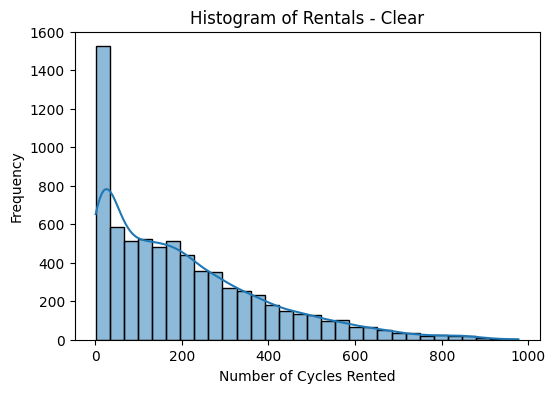

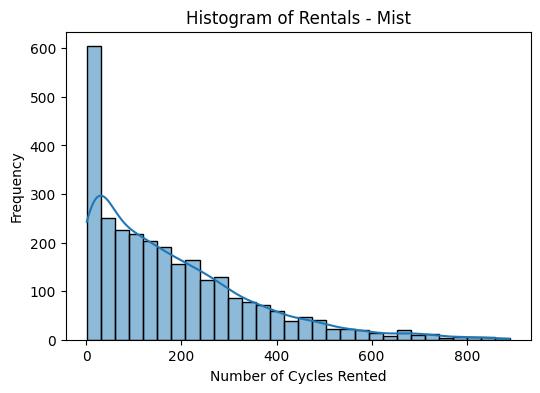

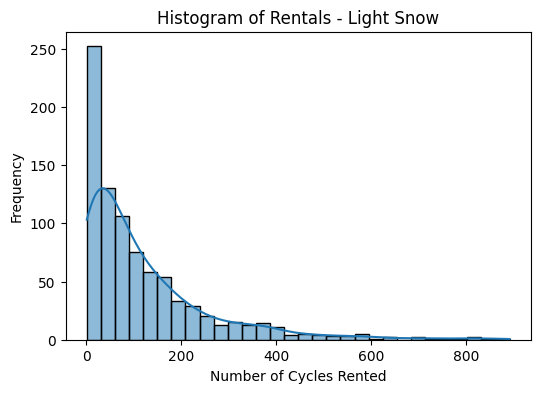

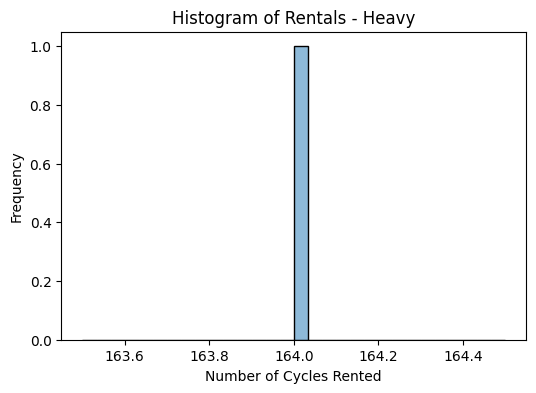

In [ ]:
# Mapping Weather

weather_map = {1: "Clear", 2: "Mist",
              3: "Light Snow", 4: "Heavy"}
df["weather_name"] = df["weather"].map(weather_map)
weathers = df["weather_name"].dropna().unique()

# Plotting Histogram for each weather

for w in weathers:
  plt.figure(figsize=(6,4))
  sns.histplot(data=df[df["weather_name"] == w],
               x="count", bins=30, kde=True)
  plt.title(f"Histogram of Rentals - {w}")
  plt.xlabel("Number of Cycles Rented")
  plt.ylabel("Frequency")
  plt.show()

<Figure size 600x400 with 0 Axes>

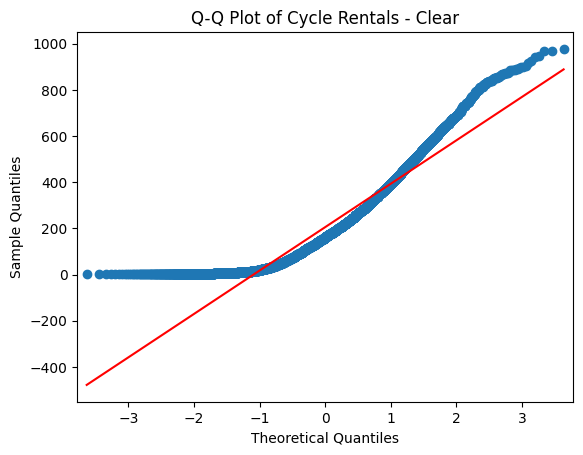

<Figure size 600x400 with 0 Axes>

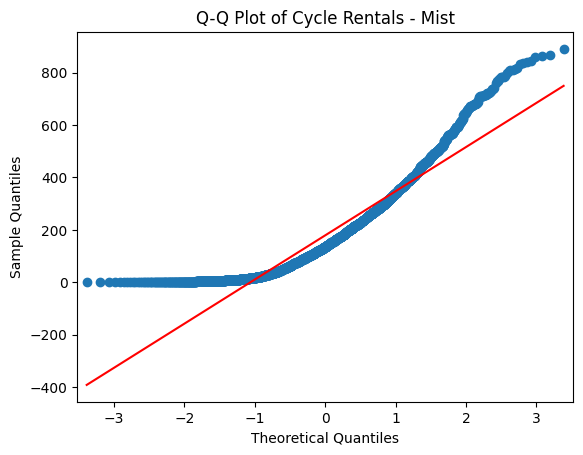

<Figure size 600x400 with 0 Axes>

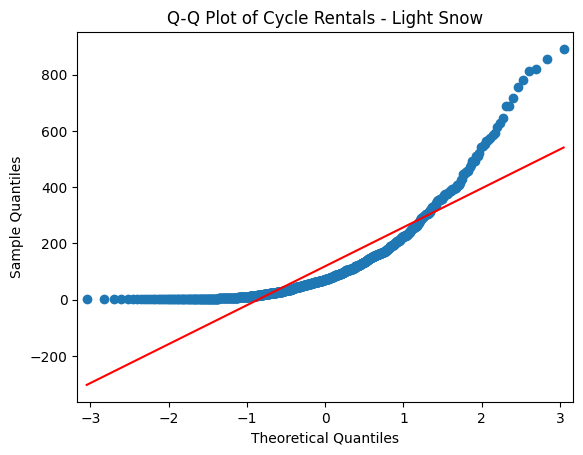

<Figure size 600x400 with 0 Axes>

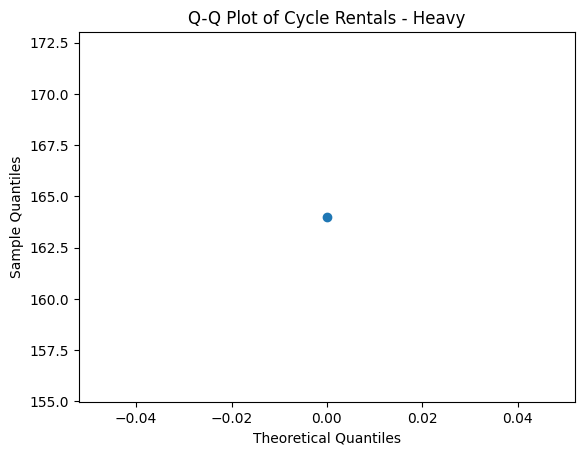

In [ ]:
# Quantile-Quantile plot for each weather

for w in weathers:
  plt.figure(figsize=(6, 4))
  sm.qqplot(df[df["weather_name"] == w]["count"], line='s')
  plt.title(f"Q-Q Plot of Cycle Rentals - {w}")
  plt.show()

In [ ]:
for w in weathers:
  data = df[df["weather_name"] == w]["count"].dropna()
  print(f"\nWeather: {w}")
  print("Sample size:", len(data))
  if len(data) < 3:
    print("Not enough data for Shapiro test")
    continue

  stat, p_value = shapiro(data)
  print(f"weather {w}: {stat:.4f}, p-value: {p_value:.4f}")

  if p_value < alpha:
    print("→ Reject H0: Data is not normally distributed")
  else:
    print("→ Fail to reject H0: Data is approximately normal")


Weather: Clear
Sample size: 7192
weather Clear: 0.8909, p-value: 0.0000
→ Reject H0: Data is not normally distributed

Weather: Mist
Sample size: 2834
weather Mist: 0.8768, p-value: 0.0000
→ Reject H0: Data is not normally distributed

Weather: Light Snow
Sample size: 859
weather Light Snow: 0.7674, p-value: 0.0000
→ Reject H0: Data is not normally distributed

Weather: Heavy
Sample size: 1
Not enough data for Shapiro test


In [ ]:
weather1 = df[df['weather'] == 1]['count']
weather2 = df[df['weather'] == 2]['count']
weather3 = df[df['weather'] == 3]['count']
weather4 = df[df['weather'] == 4]['count']

lev_stat, lev_pvalue = levene(weather1, weather2, weather3, weather4)

print(f"Levene test statistic: {lev_stat}, p-value: {lev_pvalue}")

if lev_pvalue < alpha:
    print("Reject H0: variances are significantly different")
else:
    print("Fail to reject H0: variances are approximately equal")

Levene test statistic: 54.85106195954556, p-value: 3.504937946833238e-35
Reject H0: variances are significantly different


**Step 3: Select left vs right vs 2-tailed as per hypothesis**

In [ ]:
# Two Tailed

**Step 4: Calculate p-value**

In [ ]:
# Kruskal-Wallis Test

kruskal_stat, kruskal_pvalue = kruskal(weather1, weather2, weather3, weather4)

print(f"test-statistic: {kruskal_stat}, p-value: {kruskal_pvalue}")

test-statistic: 205.00216514479087, p-value: 3.501611300708679e-44


In [ ]:
# ANOVA

f_stat, anova_pvalue = f_oneway(weather1, weather2, weather3, weather4)

print(f"F-statistic: {f_stat}, p-value: {anova_pvalue}")

F-statistic: 65.53024112793265, p-value: 5.482069475935669e-42


**Step 5: Accepting or Rejecting the Hypothesis based on p-value**

In [ ]:
if kruskal_pvalue < alpha:
  print("Reject H0: At least one weather category has a different distribution of cycle rentals.")
else:
  print("Fail to reject H0: Cycle rentals are similar across weather categories.")

Reject H0: At least one weather category has a different distribution of cycle rentals.


In [ ]:
if anova_pvalue < alpha:
  print("Reject H0: At least one weather condition has a different mean number of rented cycles.")
else:
  print("Fail to reject H0: Mean number of rented cycles is the same across all weather conditions.")

Reject H0: At least one weather condition has a different mean number of rented cycles.


Excluding the weather 4 data as it has very less data points

In [ ]:
# Kruskal-Wallis Test

kruskal_stat, kruskal_pvalue = kruskal(weather1, weather2, weather3)

print(f"test-statistic: {kruskal_stat}, p-value: {kruskal_pvalue}")

test-statistic: 204.95566833068537, p-value: 3.122066178659941e-45


In [ ]:
# ANOVA

f_stat, anova_pvalue = f_oneway(weather1, weather2, weather3)

print(f"F-statistic: {f_stat}, p-value: {anova_pvalue}")

F-statistic: 98.28356881946705, p-value: 4.976448509904196e-43


In [ ]:
if kruskal_pvalue < alpha:
  print("Reject H0: At least one weather category has a different distribution of cycle rentals.")
else:
  print("Fail to reject H0: Cycle rentals are similar across weather categories.")

Reject H0: At least one weather category has a different distribution of cycle rentals.


In [ ]:
if anova_pvalue < alpha:
  print("Reject H0: At least one weather condition has a different mean number of rented cycles.")
else:
  print("Fail to reject H0: Mean number of rented cycles is the same across all weather conditions.")

Reject H0: At least one weather condition has a different mean number of rented cycles.


## Weather dependence on season

H0: Season and weather are independent.

H1: Season and weather are associated.

### Contingency table

In [ ]:
contingency_table = pd.crosstab(df["season_name"], df["weather_name"])

print("Contingency Table:")
print(contingency_table)

Contingency Table:
weather_name  Clear  Heavy  Light Snow  Mist
season_name                                 
Fall           1930      0         199   604
Spring         1759      1         211   715
Summer         1801      0         224   708
Winter         1702      0         225   807


### Row-percentage table

In [ ]:
row_percent = contingency_table.div(contingency_table.sum(axis=1), axis=0) * 100

print("Row Percentage Table:")
print(row_percent.round(2))

Row Percentage Table:
weather_name  Clear  Heavy  Light Snow   Mist
season_name                                  
Fall          70.62   0.00        7.28  22.10
Spring        65.49   0.04        7.86  26.62
Summer        65.90   0.00        8.20  25.91
Winter        62.25   0.00        8.23  29.52


### Stacked bar chart

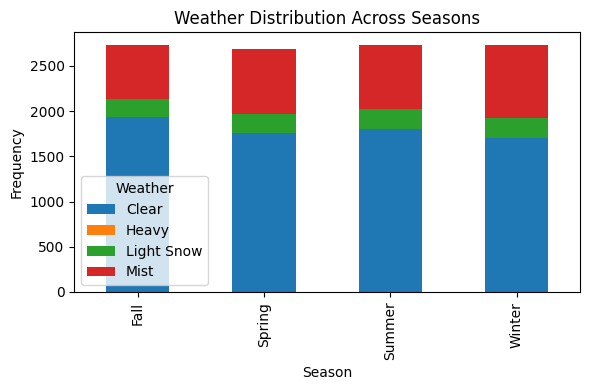

In [ ]:
contingency_table.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.title("Weather Distribution Across Seasons")
plt.xlabel("Season")
plt.ylabel("Frequency")
plt.legend(title="Weather")
plt.tight_layout()
plt.show()

### Heatmap of percentages

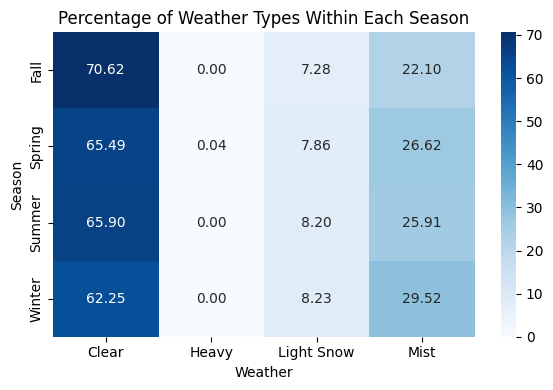

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(row_percent, annot=True, fmt=".2f", cmap="Blues")
plt.title("Percentage of Weather Types Within Each Season")
plt.xlabel("Weather")
plt.ylabel("Season")
plt.tight_layout()
plt.show()

### Chi-square test of independence

H0: Weather and season are independent (no relationship).

H1: Weather and season are dependent

In [ ]:
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square Statistic:", chi2)
print("p-value:", p)
print("Degrees of Freedom:", dof)

expected_df = pd.DataFrame(expected,
                           index=contingency_table.index,
                           columns=contingency_table.columns)

print(expected_df.round(2))

Chi-square Statistic: 49.158655596893624
p-value: 1.549925073686492e-07
Degrees of Freedom: 9
weather_name    Clear  Heavy  Light Snow    Mist
season_name                                     
Fall          1805.60   0.25      215.66  711.49
Spring        1774.55   0.25      211.95  699.26
Summer        1805.60   0.25      215.66  711.49
Winter        1806.26   0.25      215.74  711.75


In this dataset, weather category 4 (Heavy) is almost absent, so the chi-square assumption is violated if we keep it.

In [ ]:
df_valid = df[df["weather"] != 4].copy()

contingency_table_valid = pd.crosstab(df_valid["season_name"], df_valid["weather_name"])

print("Adjusted Contingency Table (without Heavy):")
print(contingency_table_valid)

chi2_valid, p_valid, dof_valid, expected_valid = chi2_contingency(contingency_table_valid)

expected_valid_df = pd.DataFrame(expected_valid,
                                 index=contingency_table_valid.index,
                                 columns=contingency_table_valid.columns)

print("\nAdjusted Chi-square Statistic:", chi2_valid)
print("Adjusted p-value:", p_valid)
print("Adjusted Degrees of Freedom:", dof_valid)

print("\nAdjusted Expected Frequencies:")
print(expected_valid_df.round(2))

Adjusted Contingency Table (without Heavy):
weather_name  Clear  Light Snow  Mist
season_name                          
Fall           1930         199   604
Spring         1759         211   715
Summer         1801         224   708
Winter         1702         225   807

Adjusted Chi-square Statistic: 46.10145731073249
Adjusted p-value: 2.8260014509929343e-08
Adjusted Degrees of Freedom: 6

Adjusted Expected Frequencies:
weather_name    Clear  Light Snow    Mist
season_name                              
Fall          1805.76      215.68  711.56
Spring        1774.05      211.89  699.06
Summer        1805.76      215.68  711.56
Winter        1806.42      215.76  711.82


In [ ]:
if p_valid < alpha:
  print("Reject H0: Weather and season are associated")
else:
  print("Fail to reject H0: Weather and season are independent")

Reject H0: Weather and season are associated


# Report

## Data Observations

* **Total Rows**: 10886  
* **Total Columns**: 12  
* **Missing Values**: No missing values were found.

* **Data Preparation**:
  - Columns such as `season`, `holiday`, `workingday`, and `weather` were treated as categorical because they represent encoded categories rather than continuous numeric values.
  - Duplicate records were not observed.

* **Outlier Assessment**:
  1. Numerical variables such as humidity, windspeed, and count show skewness and visible outliers.
  2. Outliers were not removed because they can reflect peak-demand periods or real weather variation rather than data-entry errors.

* **Univariate Insights**:
  1. `count` is right-skewed, with many moderate-demand observations and fewer high-demand peaks.
  2. Registered users contribute more consistently to demand than casual users.
  3. Weather category 1 (Clear) and workingday = 1 are the most common categories in the dataset.

* **Bivariate Insights**:
  1. Median rentals are slightly higher on working days, but this difference is not statistically significant.
  2. Season 3 (Fall) shows the strongest rental demand, while lower demand is observed in less favorable seasons.
  3. Clear weather is associated with higher rental counts, and demand decreases in poorer weather conditions.
  4. Temperature and apparent temperature show positive association with rentals, while humidity tends to show a negative relationship.

# Conclusion

### 1. Working Day vs Number of Cycles Rented
The statistical comparison between working days and non-working days did **not** show a significant difference in rentals (`p > 0.05`). Therefore, we **fail to reject the null hypothesis** and conclude that working-day status does not have a statistically significant impact on rental demand.

### 2. Season vs Number of Cycles Rented
Both ANOVA and the Kruskal-Wallis test showed a statistically significant difference in rentals across seasons (`p < 0.05`). Since the normality and equal-variance assumptions are not fully satisfied, the **Kruskal-Wallis result was considered for final inference**. We  **reject the null hypothesis** and conclude that season has a significant effect on bike rental demand.

### 3. Weather vs Number of Cycles Rented
Rental demand also varies significantly across weather conditions (`p < 0.05`). Because extreme weather category 4 has very few observations, but the overall conclusion remains clear: weather significantly affects rentals. We therefore **reject the null hypothesis** and conclude that more favorable weather is associated with higher rental demand. Since the normality and equal-variance assumptions are not fully satisfied, the **Kruskal-Wallis result was considered for final inference**.

### 4. Weather Dependence on Season
The chi-square test of independence showed a statistically significant association between season and weather (`p < 0.05`). Therefore, we **reject the null hypothesis** and conclude that season and weather are statistically associated.

## Final Business Takeaway
Overall, Yulu demand is driven much more strongly by **environmental conditions** than by whether a day is a working day. Season and weather emerge as the most important explanatory factors in this case study.

# Recommendations

1. **Adopt season-based bike availability planning**  
   Increase bike availability, charging readiness, and maintenance capacity during high-demand seasons, and reduce idle inventory during weaker seasons.

2. **Use weather-driven demand forecasting**  
   Integrate short-term weather forecasts into operational planning so bikes can be redistributed before high-demand days.

3. **Run targeted promotions during weak-demand periods**  
   Use discounts, cashback, ride passes, or loyalty rewards during poor weather or lower-demand seasons to stabilize demand.

4. **Implement dynamic pricing**  
   Premium pricing can be considered during high-demand periods, while promotional pricing can help improve utilization when weather conditions reduces demand.

5. **Prioritize operational readiness in favorable weather**  
   On clear-weather days, ensure higher bike availability, stronger charging support, and better app visibility because these periods generate the highest demand.

6. **Improve station-level and zone-level forecasting**  
   Use historical demand, seasonality, weather, and local area behavior to determine where additional bikes should be positioned.

7. **Allocate marketing spend more effectively**  
   Focus marketing campaigns around favorable seasons and weather windows, rather than relying mainly on working-day vs non-working-day segmentation.

8. **Use season and weather jointly in business decisions**  
   Since season and weather are statistically associated, Yulu should evaluate them together when forecasting demand, designing offers, and planning operations.

9. **Monitor low-frequency extreme weather separately**  
   Because extreme weather has very few observations in this dataset, Yulu should collect more such data before making strong policy decisions for that segment.